BALANCED DATA PREPARATION


In [1]:
!pip install albumentations opencv-python --break-system-packages

  Using cached albumentations-2.0.8-py3-none-any.whl.metadata (43 kB)
  Using cached pydantic-2.12.5-py3-none-any.whl.metadata (90 kB)
  Using cached albucore-0.0.24-py3-none-any.whl.metadata (5.3 kB)
  Using cached opencv_python_headless-4.13.0.92-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached stringzilla-4.6.0-cp313-cp313-win_amd64.whl.metadata (124 kB)
  Using cached simsimd-6.5.12-cp313-cp313-win_amd64.whl.metadata (71 kB)
  Using cached annotated_types-0.7.0-py3-none-any.whl.metadata (15 kB)
  Using cached pydantic_core-2.41.5-cp313-cp313-win_amd64.whl.metadata (7.4 kB)
  Using cached typing_inspection-0.4.2-py3-none-any.whl.metadata (2.6 kB)
Using cached albumentations-2.0.8-py3-none-any.whl (369 kB)
Using cached albucore-0.0.24-py3-none-any.whl (15 kB)
Using cached opencv_python_headless-4.13.0.92-cp37-abi3-win_amd64.whl (40.1 MB)
Using cached pydantic-2.12.5-py3-none-any.whl (463 kB)
Using cached pydantic_core-2.41.5-cp313-cp313-win_amd64.whl (2.0 MB)
Using cached anno


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


🔍 Testing augmentation quality...


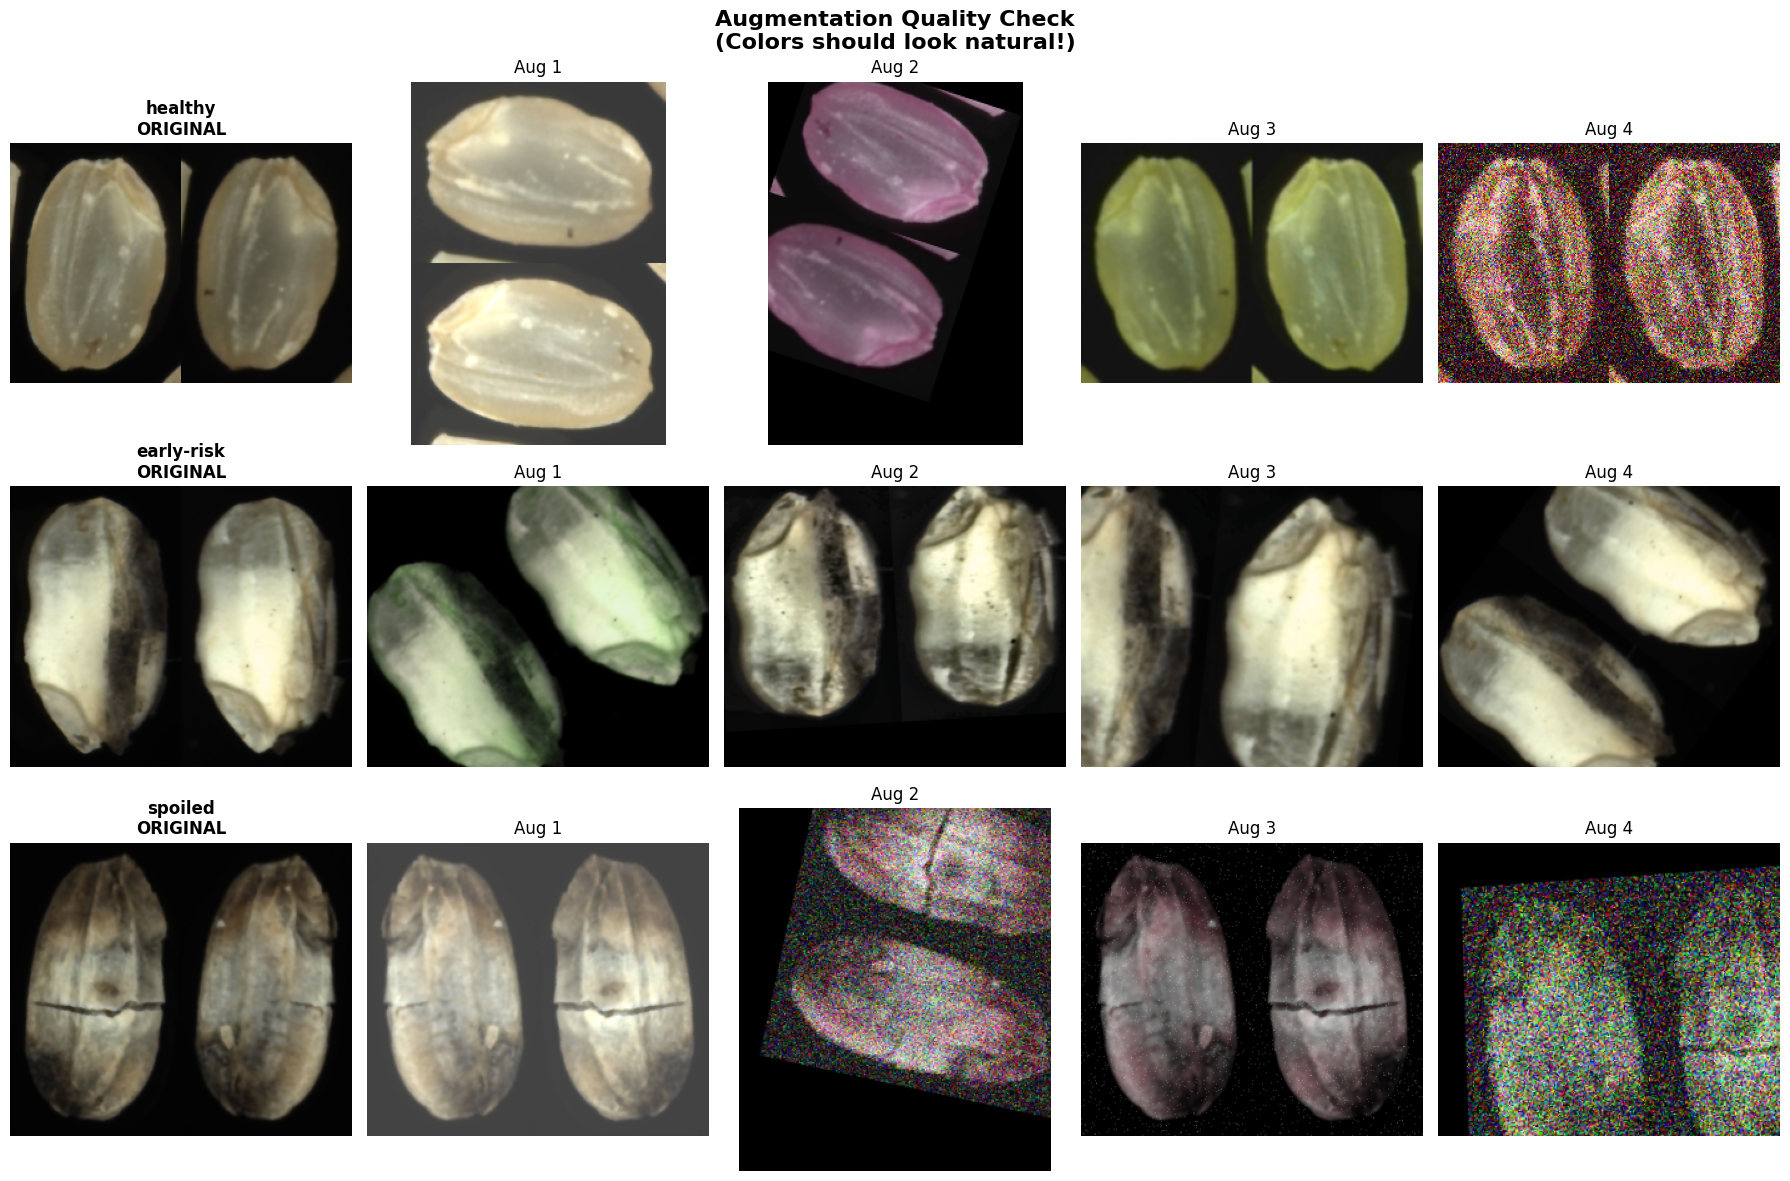


⚠️  CRITICAL CHECK:
✅ Good: Rice is white/cream, mold is black/brown, natural colors
❌ Bad: Blue/purple/green rice, extreme colors, unrealistic

If images look good → proceed with full augmentation
If images look bad → adjust parameters further


In [3]:
import matplotlib.pyplot as plt
import cv2
import random

print("🔍 Testing augmentation quality...")

fig, axes = plt.subplots(3, 5, figsize=(18, 12))
fig.suptitle('Augmentation Quality Check\n(Colors should look natural!)', 
             fontsize=16, fontweight='bold')

for row, cls in enumerate(['healthy', 'early-risk', 'spoiled']):
    images = list((train_dir / cls).glob('*.png'))
    sample_img = random.choice(images)
    
    # Original
    orig = cv2.imread(str(sample_img))
    orig_rgb = cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)
    axes[row, 0].imshow(orig_rgb)
    axes[row, 0].set_title(f'{cls}\nORIGINAL', fontweight='bold')
    axes[row, 0].axis('off')
    
    # 4 augmented versions
    for col in range(1, 5):
        aug = transform(image=orig_rgb)
        axes[row, col].imshow(aug['image'])
        axes[row, col].set_title(f'Aug {col}')
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

print("\n⚠️  CRITICAL CHECK:")
print("✅ Good: Rice is white/cream, mold is black/brown, natural colors")
print("❌ Bad: Blue/purple/green rice, extreme colors, unrealistic")
print("\nIf images look good → proceed with full augmentation")
print("If images look bad → adjust parameters further")

In [7]:
import os
import cv2
import numpy as np
import shutil
from pathlib import Path
from tqdm import tqdm
import albumentations as A
import random

# Set seeds for reproducibility
random.seed(42)
np.random.seed(42)

# Config
DATASET_ROOT = r'D:\Research\rice\organized_dataset'
OUTPUT_ROOT = r'D:\Research\rice\balanced_augmented_dataset'

# Target counts (adjust as needed)
TARGET_PER_CLASS = 3500  # 3,500 images per class

print("="*70)
print("BALANCED DATA PREPARATION")
print("="*70)

# Check current distribution
train_dir = Path(DATASET_ROOT) / 'train'
test_dir = Path(DATASET_ROOT) / 'test'

print("\n Current Distribution:")
print("\nTRAIN:")
for cls in ['healthy', 'early-risk', 'spoiled']:
    count = len(list((train_dir / cls).glob('*.png')))
    print(f"  {cls:12s}: {count:,} images")

print("\nTEST:")
for cls in ['healthy', 'early-risk', 'spoiled']:
    count = len(list((test_dir / cls).glob('*.png')))
    print(f"  {cls:12s}: {count:,} images")

# Create output structure
output_train = Path(OUTPUT_ROOT) / 'train'
output_test = Path(OUTPUT_ROOT) / 'test'

for subset in [output_train, output_test]:
    for cls in ['healthy', 'early-risk', 'spoiled']:
        (subset / cls).mkdir(parents=True, exist_ok=True)

# Define augmentation pipeline
transform = A.Compose([
    A.OneOf([
        A.HorizontalFlip(p=1.0),
        A.VerticalFlip(p=1.0),
        A.Rotate(limit=90, p=1.0),
        A.RandomRotate90(p=1.0),
    ], p=0.9),

       A.OneOf([
        A.GaussianBlur(blur_limit=(3, 7), p=1.0),      # Out of focus
        A.MotionBlur(blur_limit=7, p=1.0),             # Camera shake
        A.MedianBlur(blur_limit=5, p=1.0),             # Soft blur
        A.Defocus(radius=(1, 3), alias_blur=(0.1, 0.3), p=1.0),  # Poor focus
    ], p=0.6),
    
  A.RandomBrightnessContrast(
        brightness_limit=0.15,   # Very conservative
        contrast_limit=0.15,     # Very conservative
        p=0.7
    ),
    
    # 3. Spatial transforms (safe)
    A.ShiftScaleRotate(
        shift_limit=0.1,
        scale_limit=0.15,
        rotate_limit=20,
        border_mode=0,  # Constant border
        p=0.6
    ),

      # 5. Image quality degradation (cheap camera sensor)
    A.OneOf([
        A.ISONoise(
            color_shift=(0.01, 0.02),  # VERY MILD (not rainbow!)
            intensity=(0.1, 0.3),
            p=1.0
        ),
        A.ImageCompression(quality_lower=60, quality_upper=90, p=1.0),  # JPEG artifacts
    ], p=0.4),
    
   
    
   
])

def augment_image(image_path):
    """Apply augmentation to image."""
    img = cv2.imread(str(image_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    augmented = transform(image=img_rgb)
    aug_img = cv2.cvtColor(augmented['image'], cv2.COLOR_RGB2BGR)
    return aug_img

print("\n" + "="*70)
print("STEP 1: PROCESSING TRAINING SET")
print("="*70)

# 1. HEALTHY - Downsample
print(f"\n📉 Downsampling healthy (18,000 → {TARGET_PER_CLASS})...")
healthy_images = list((train_dir / 'healthy').glob('*.png'))
selected_healthy = np.random.choice(healthy_images, size=TARGET_PER_CLASS, replace=False)

for img_path in tqdm(selected_healthy, desc="Copying healthy"):
    shutil.copy2(img_path, output_train / 'healthy' / img_path.name)

# 2. EARLY-RISK - Massive augmentation
print(f"\n🔄 Augmenting early-risk (130 → {TARGET_PER_CLASS})...")
early_images = list((train_dir / 'early-risk').glob('*.png'))
print(f"  Original images: {len(early_images)}")
print(f"  Augmentation needed: {TARGET_PER_CLASS - len(early_images)}")

# Copy originals
for img_path in tqdm(early_images, desc="Copying original early-risk"):
    shutil.copy2(img_path, output_train / 'early-risk' / img_path.name)

# Generate augmented
augmented_count = 0
target_aug = TARGET_PER_CLASS - len(early_images)

pbar = tqdm(total=target_aug, desc="Augmenting early-risk")
while augmented_count < target_aug:
    source_img = random.choice(early_images)
    aug_img = augment_image(source_img)
    
    output_path = output_train / 'early-risk' / f'aug_{augmented_count:05d}_{source_img.stem}.png'
    cv2.imwrite(str(output_path), aug_img)
    
    augmented_count += 1
    pbar.update(1)
pbar.close()

# 3. SPOILED - Moderate augmentation
print(f"\n🔄 Augmenting spoiled (1,220 → {TARGET_PER_CLASS})...")
spoiled_images = list((train_dir / 'spoiled').glob('*.png'))
print(f"  Original images: {len(spoiled_images)}")
print(f"  Augmentation needed: {TARGET_PER_CLASS - len(spoiled_images)}")

# Copy originals
for img_path in tqdm(spoiled_images, desc="Copying original spoiled"):
    shutil.copy2(img_path, output_train / 'spoiled' / img_path.name)

# Generate augmented
augmented_count = 0
target_aug = TARGET_PER_CLASS - len(spoiled_images)

pbar = tqdm(total=target_aug, desc="Augmenting spoiled")
while augmented_count < target_aug:
    source_img = random.choice(spoiled_images)
    aug_img = augment_image(source_img)
    
    output_path = output_train / 'spoiled' / f'aug_{augmented_count:05d}_{source_img.stem}.png'
    cv2.imwrite(str(output_path), aug_img)
    
    augmented_count += 1
    pbar.update(1)
pbar.close()

print("\n" + "="*70)
print("STEP 2: COPYING TEST SET (NO AUGMENTATION)")
print("="*70)

print("\n📋 Copying test set as-is (test set should NOT be augmented)...")
for cls in ['healthy', 'early-risk', 'spoiled']:
    test_images = list((test_dir / cls).glob('*.png'))
    for img_path in tqdm(test_images, desc=f"Test {cls}"):
        shutil.copy2(img_path, output_test / cls / img_path.name)

print("\n" + "="*70)
print("FINAL VERIFICATION")
print("="*70)

print("\nTRAIN SET (Balanced):")
train_total = 0
for cls in ['healthy', 'early-risk', 'spoiled']:
    count = len(list((output_train / cls).glob('*.png')))
    train_total += count
    pct = (count / train_total * 100) if train_total > 0 else 0
    print(f"  {cls:12s}: {count:,} images")

print(f"\n  TOTAL: {train_total:,} images")
ratio_h = train_total / 3 if train_total > 0 else 0
print(f"  Ratio: 1:1:1 (perfect balance!)")

print("\nTEST SET (Original - Imbalanced is OK):")
test_total = 0
for cls in ['healthy', 'early-risk', 'spoiled']:
    count = len(list((output_test / cls).glob('*.png')))
    test_total += count
    print(f"  {cls:12s}: {count:,} images")

print(f"\n  TOTAL: {test_total:,} images")

print(f"\n📁 Output location:")
print(f"   Train: {output_train}")
print(f"   Test:  {output_test}")

print("\n" + "="*70)
print("✅ BALANCING COMPLETE!")
print("="*70)
print("\n💡 Key Points:")
print("  ✓ Train set is perfectly balanced (1:1:1)")
print("  ✓ Test set kept original (reflects real-world distribution)")
print("  ✓ Ready for model training!")

C:\Users\DELL\AppData\Local\Temp\ipykernel_18664\2293251849.py:86: UserWarning: Argument(s) 'quality_lower, quality_upper' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=60, quality_upper=90, p=1.0),  # JPEG artifacts


BALANCED DATA PREPARATION

 Current Distribution:

TRAIN:
  healthy     : 18,000 images
  early-risk  : 130 images
  spoiled     : 1,220 images

TEST:
  healthy     : 2,000 images
  early-risk  : 13 images
  spoiled     : 137 images

STEP 1: PROCESSING TRAINING SET

📉 Downsampling healthy (18,000 → 3500)...


Copying healthy: 100%|██████████| 3500/3500 [00:03<00:00, 924.30it/s] 



🔄 Augmenting early-risk (130 → 3500)...
  Original images: 130
  Augmentation needed: 3370


Augmenting early-risk: 100%|██████████| 3370/3370 [00:25<00:00, 131.72it/s]



🔄 Augmenting spoiled (1,220 → 3500)...
  Original images: 1220
  Augmentation needed: 2280


Augmenting spoiled: 100%|██████████| 2280/2280 [00:19<00:00, 118.94it/s]



STEP 2: COPYING TEST SET (NO AUGMENTATION)

📋 Copying test set as-is (test set should NOT be augmented)...


Test spoiled: 100%|██████████| 137/137 [00:00<00:00, 879.82it/s]



FINAL VERIFICATION

TRAIN SET (Balanced):
  healthy     : 3,500 images
  early-risk  : 3,500 images
  spoiled     : 3,500 images

  TOTAL: 10,500 images
  Ratio: 1:1:1 (perfect balance!)

TEST SET (Original - Imbalanced is OK):
  healthy     : 2,000 images
  early-risk  : 13 images
  spoiled     : 137 images

  TOTAL: 2,150 images

📁 Output location:
   Train: D:\Research\rice\balanced_augmented_dataset\train
   Test:  D:\Research\rice\balanced_augmented_dataset\test

✅ BALANCING COMPLETE!

💡 Key Points:
  ✓ Train set is perfectly balanced (1:1:1)
  ✓ Test set kept original (reflects real-world distribution)
  ✓ Ready for model training!


CLASSIFICATION VERIFICATION


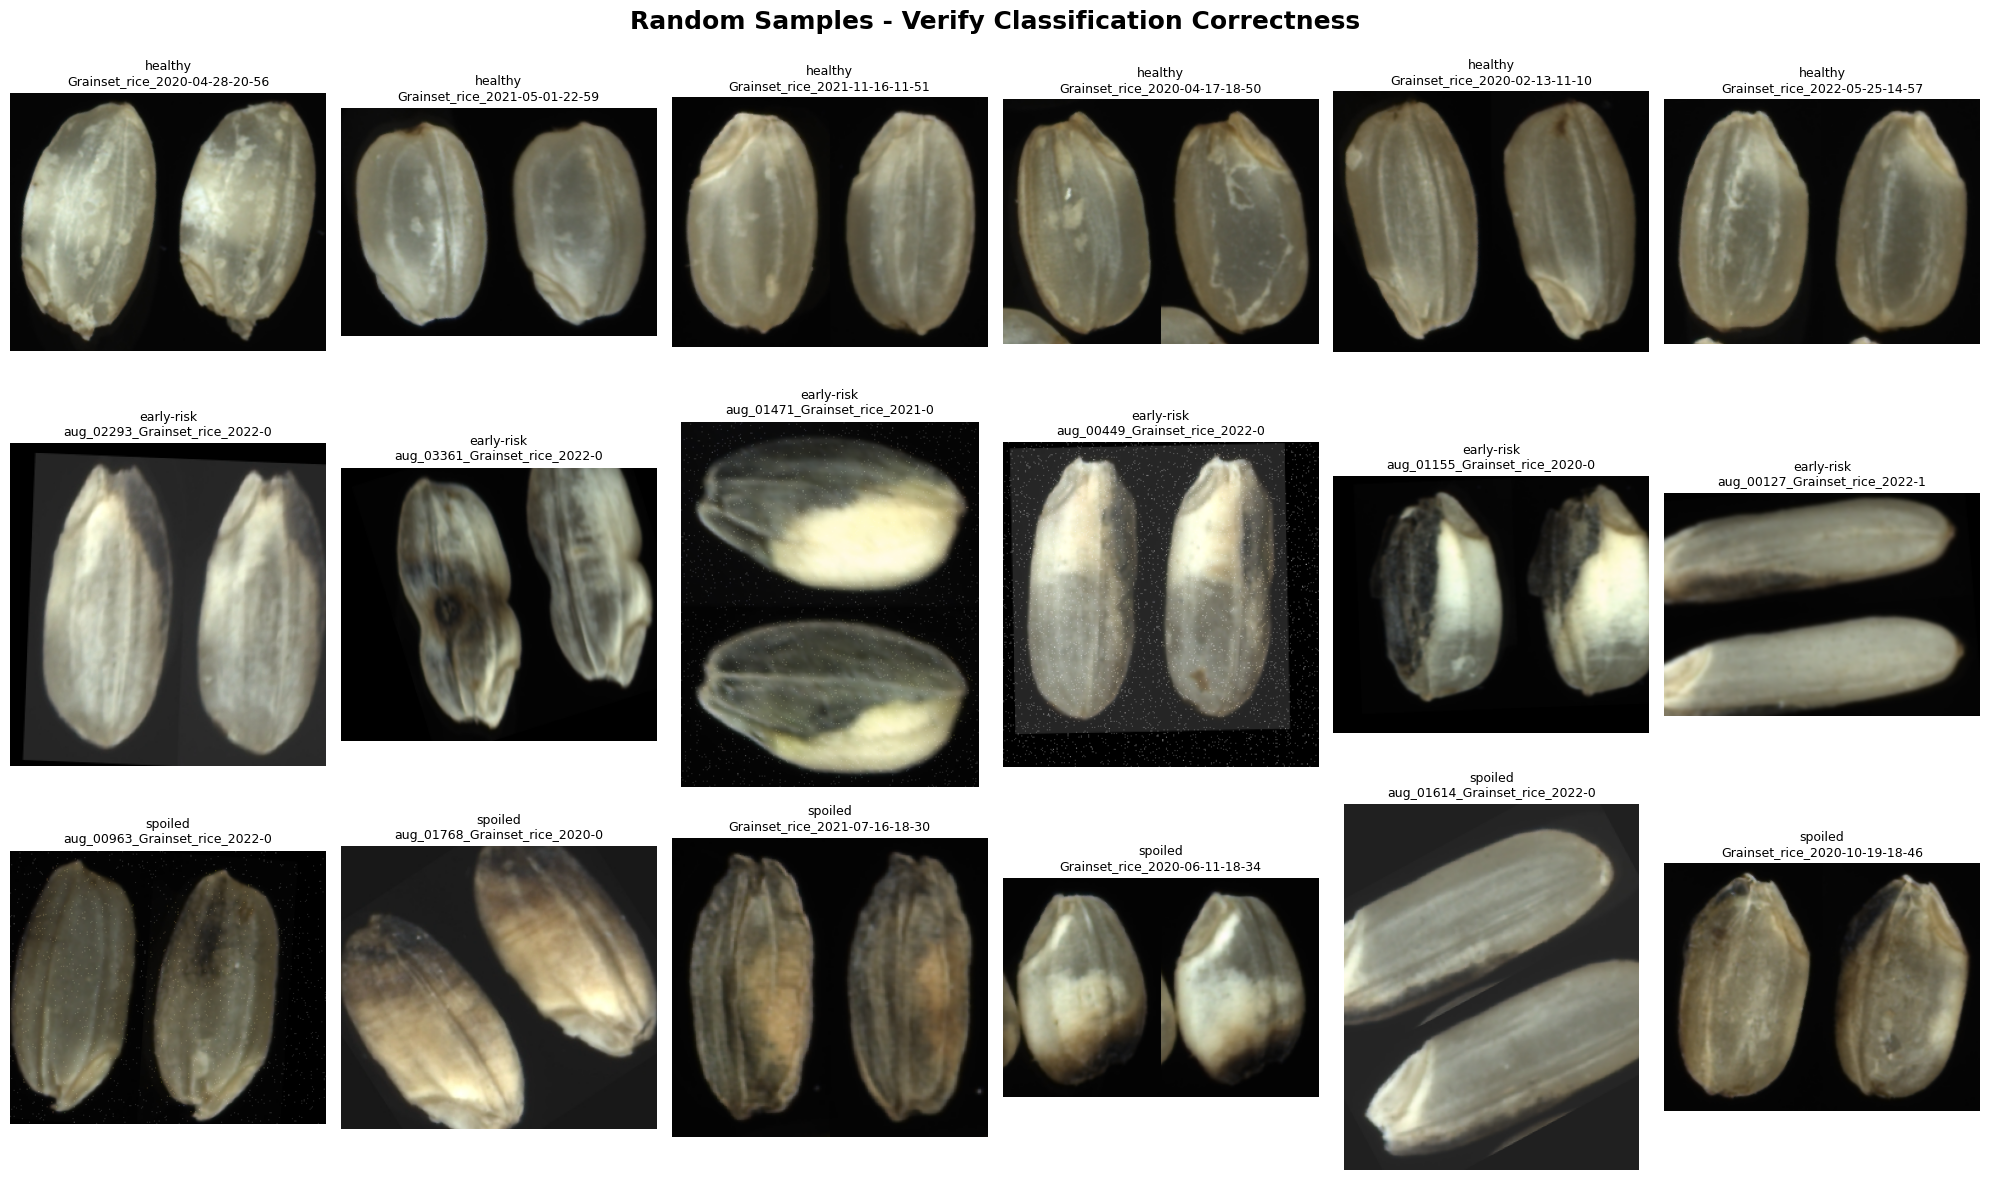


VERIFICATION CHECKLIST:

✅ HEALTHY should show:
   - Clean white/cream rice grains
   - NO dark spots or discoloration
   - NO mold visible

✅ EARLY-RISK should show:
   - Mostly white rice with SMALL dark spots
   - Light/minor mold contamination
   - Early signs of spoilage

✅ SPOILED should show:
   - HEAVY mold coverage
   - Large dark/black areas
   - Significant contamination



In [8]:
"""
VERIFY AUGMENTED DATASET CLASSIFICATION
========================================
Display random samples to check if images are in correct folders
"""

import cv2
import matplotlib.pyplot as plt
import random
from pathlib import Path

DATASET_ROOT = r'D:\Research\rice\balanced_augmented_dataset\train'

print("="*70)
print("CLASSIFICATION VERIFICATION")
print("="*70)

# Sample images from each class
fig, axes = plt.subplots(3, 6, figsize=(20, 12))
fig.suptitle('Random Samples - Verify Classification Correctness', fontsize=18, fontweight='bold')

for row, cls in enumerate(['healthy', 'early-risk', 'spoiled']):
    class_dir = Path(DATASET_ROOT) / cls
    all_images = list(class_dir.glob('*.png'))
    
    # Get random samples
    samples = random.sample(all_images, 6)
    
    for col, img_path in enumerate(samples):
        img = cv2.imread(str(img_path))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        axes[row, col].imshow(img_rgb)
        axes[row, col].set_title(f'{cls}\n{img_path.stem[:30]}', fontsize=9)
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("VERIFICATION CHECKLIST:")
print("="*70)
print("\n✅ HEALTHY should show:")
print("   - Clean white/cream rice grains")
print("   - NO dark spots or discoloration")
print("   - NO mold visible")

print("\n✅ EARLY-RISK should show:")
print("   - Mostly white rice with SMALL dark spots")
print("   - Light/minor mold contamination")
print("   - Early signs of spoilage")

print("\n✅ SPOILED should show:")
print("   - HEAVY mold coverage")
print("   - Large dark/black areas")
print("   - Significant contamination")

print("\n" + "="*70)


POST-AUGMENTATION ANALYSIS

📊 FINAL DATASET DISTRIBUTION:

TRAINING SET:
  healthy     :  3,500 images ( 33.3%)
  early-risk  :  3,500 images ( 33.3%)
  spoiled     :  3,500 images ( 33.3%)
  TOTAL       : 10,500 images

TEST SET:
  healthy     :  2,000 images ( 93.0%)
  early-risk  :     13 images (  0.6%)
  spoiled     :    137 images (  6.4%)
  TOTAL       :  2,150 images

BALANCE QUALITY ASSESSMENT

🔢 Balance Metrics:
  Min class size: 3,500
  Max class size: 3,500
  Ratio (max:min): 1.00:1

✅ Balance Status: PERFECT

AUGMENTATION STATISTICS

📈 Per-Class Augmentation:

HEALTHY:
  Original:    3,500
  Augmented:       0 (0.0%)
  Total:       3,500
  Multiplier: 1.00×

EARLY-RISK:
  Original:      130
  Augmented:   3,370 (96.3%)
  Total:       3,500
  Multiplier: 26.92×

SPOILED:
  Original:    1,220
  Augmented:   2,280 (65.1%)
  Total:       3,500
  Multiplier: 2.87×

GENERATING VISUALIZATION


C:\Users\DELL\AppData\Local\Temp\ipykernel_18664\2982937913.py:259: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
C:\Users\DELL\AppData\Local\Temp\ipykernel_18664\2982937913.py:259: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\DELL\AppData\Local\Temp\ipykernel_18664\2982937913.py:263: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(viz_path, dpi=300, bbox_inches='tight')
C:\Users\DELL\AppData\Local\Temp\ipykernel_18664\2982937913.py:263: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.savefig(viz_path, dpi=300, bbox_inches='tight')



✅ Visualization saved: D:\Research\rice\balanced_augmented_dataset\augmentation_analysis.png


d:\Research\Mobile-Rice-Mold-Spoilage-Detection-System\rice_mold_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Research\Mobile-Rice-Mold-Spoilage-Detection-System\rice_mold_env\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


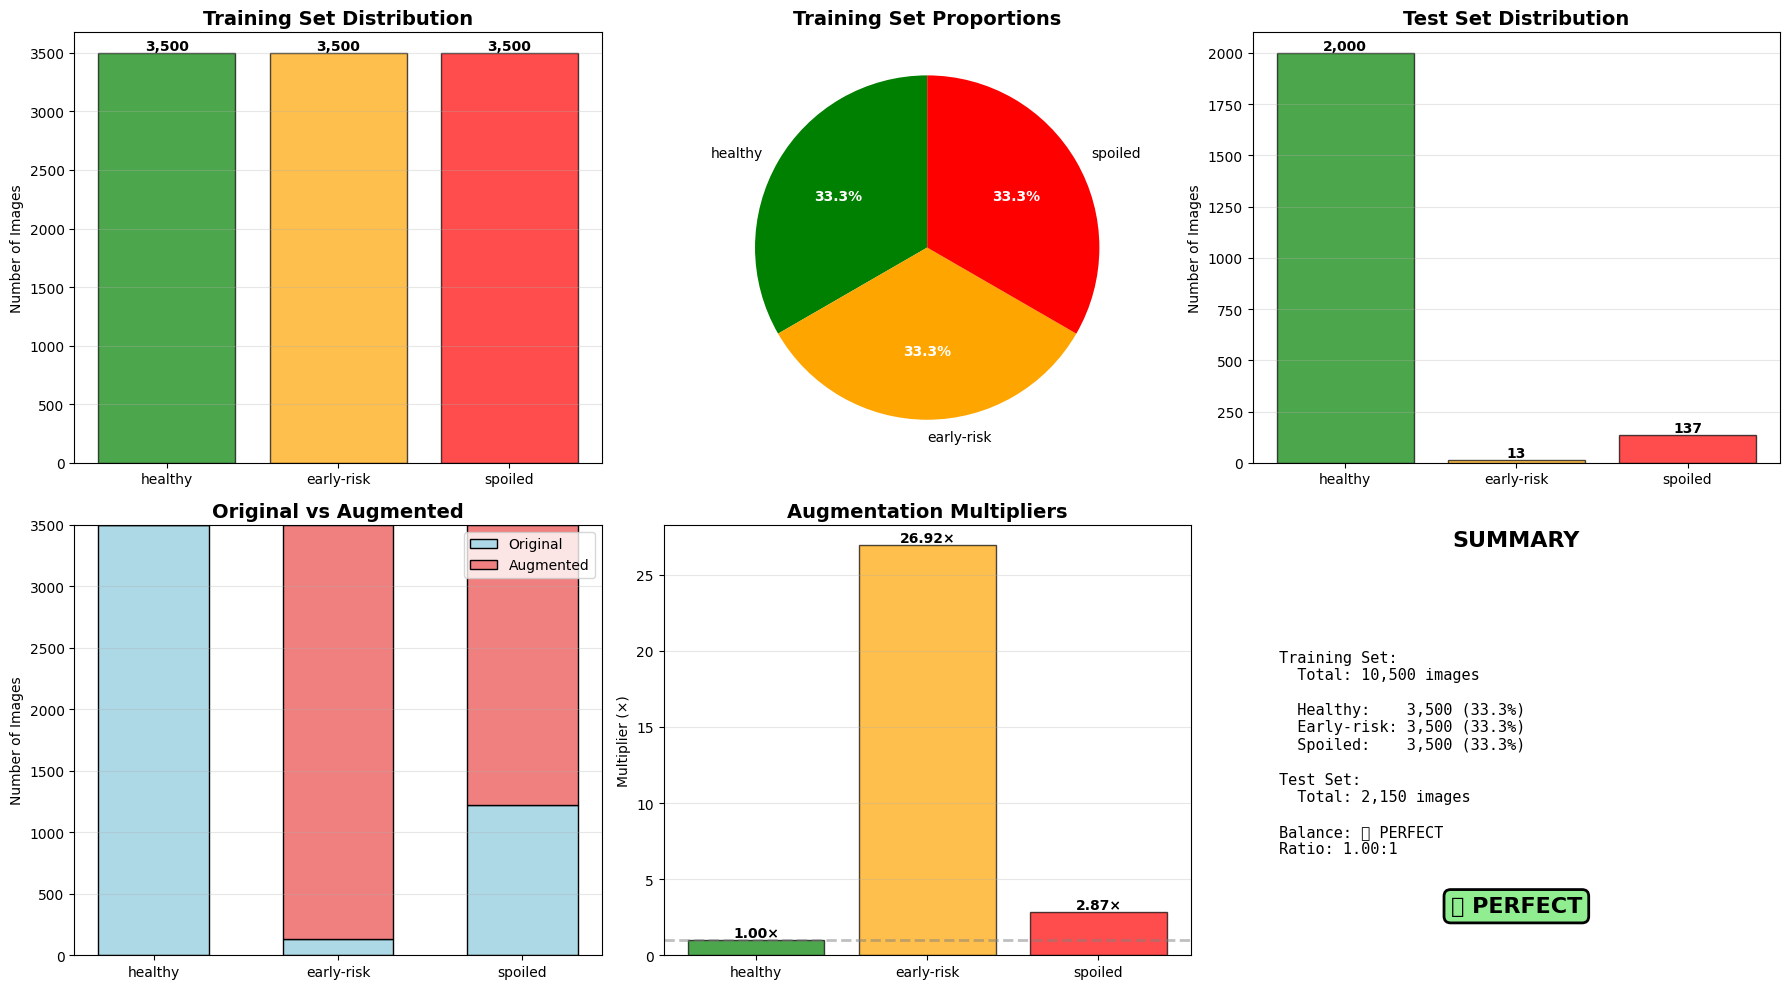


EXPORTING SUMMARY
✅ Summary saved: D:\Research\rice\balanced_augmented_dataset\augmentation_summary.json

RECOMMENDATIONS & NEXT STEPS

📋 Based on augmentation results:

✅ CLASS BALANCE: PERFECT
   No additional augmentation needed.
   Dataset is ready for splitting.

🎯 NEXT STEPS:
   1. ✅ Proceed to validation split
   2. ✅ Create train/val/test structure
   3. ✅ Begin model training

✅ AUGMENTATION & ANALYSIS COMPLETE!

📁 Output Location:
   D:\Research\rice\balanced_augmented_dataset

📊 Generated Files:
   - augmentation_analysis.png
   - augmentation_summary.json

Dataset Status: ✅ PERFECT
Ready for next step: YES



In [9]:
# ============================================================================
# IMMEDIATE POST-AUGMENTATION ANALYSIS
# Run this right after augmentation completes
# ============================================================================

print("\n" + "="*70)
print("POST-AUGMENTATION ANALYSIS")
print("="*70)

# ============================================================================
# ANALYSIS 1: Verify Final Counts
# ============================================================================

print("\n📊 FINAL DATASET DISTRIBUTION:\n")

# Count files in each category
def count_files(directory, category):
    """Count images in directory."""
    cat_path = Path(directory) / category
    if not cat_path.exists():
        return 0
    return len(list(cat_path.glob('*.png'))) + len(list(cat_path.glob('*.jpg')))

train_final = {}
test_final = {}

for cls in ['healthy', 'early-risk', 'spoiled']:
    train_final[cls] = count_files(output_train, cls)
    test_final[cls] = count_files(output_test, cls)

print("TRAINING SET:")
train_total = sum(train_final.values())
for cls in ['healthy', 'early-risk', 'spoiled']:
    count = train_final[cls]
    pct = (count / train_total * 100) if train_total > 0 else 0
    print(f"  {cls:12s}: {count:6,d} images ({pct:5.1f}%)")
print(f"  {'TOTAL':12s}: {train_total:6,d} images")

print("\nTEST SET:")
test_total = sum(test_final.values())
for cls in ['healthy', 'early-risk', 'spoiled']:
    count = test_final[cls]
    pct = (count / test_total * 100) if test_total > 0 else 0
    print(f"  {cls:12s}: {count:6,d} images ({pct:5.1f}%)")
print(f"  {'TOTAL':12s}: {test_total:6,d} images")


# ============================================================================
# ANALYSIS 2: Balance Quality Check
# ============================================================================

print("\n" + "="*70)
print("BALANCE QUALITY ASSESSMENT")
print("="*70)

# Calculate ratios
min_count = min(train_final.values())
max_count = max(train_final.values())
ratio = max_count / min_count if min_count > 0 else float('inf')

print(f"\n🔢 Balance Metrics:")
print(f"  Min class size: {min_count:,}")
print(f"  Max class size: {max_count:,}")
print(f"  Ratio (max:min): {ratio:.2f}:1")

# Evaluate balance
if ratio <= 1.1:
    balance_status = "PERFECT"
    balance_color = "green"
    balance_symbol = "✅"
elif ratio <= 1.5:
    balance_status = "EXCELLENT"
    balance_color = "green"
    balance_symbol = "✅"
elif ratio <= 3.0:
    balance_status = "GOOD"
    balance_color = "orange"
    balance_symbol = "⚠️"
else:
    balance_status = "POOR"
    balance_color = "red"
    balance_symbol = "❌"

print(f"\n{balance_symbol} Balance Status: {balance_status}")

if balance_status == "POOR":
    print("\n💡 Recommendations:")
    target = int(max_count / 1.2)  # Target for balance
    for cls in ['healthy', 'early-risk', 'spoiled']:
        if train_final[cls] < target:
            needed = target - train_final[cls]
            print(f"  - Augment {cls} by {needed:,} more images")


# ============================================================================
# ANALYSIS 3: Augmentation Statistics
# ============================================================================

print("\n" + "="*70)
print("AUGMENTATION STATISTICS")
print("="*70)

print("\n📈 Per-Class Augmentation:\n")

for cls in ['healthy', 'early-risk', 'spoiled']:
    # Count original vs augmented
    cat_path = output_train / cls
    all_files = list(cat_path.glob('*.png'))
    
    augmented = [f for f in all_files if f.name.startswith('aug_')]
    original = [f for f in all_files if not f.name.startswith('aug_')]
    
    total = len(all_files)
    aug_count = len(augmented)
    orig_count = len(original)
    aug_pct = (aug_count / total * 100) if total > 0 else 0
    multiplier = (total / orig_count) if orig_count > 0 else 0
    
    print(f"{cls.upper()}:")
    print(f"  Original:   {orig_count:6,d}")
    print(f"  Augmented:  {aug_count:6,d} ({aug_pct:.1f}%)")
    print(f"  Total:      {total:6,d}")
    print(f"  Multiplier: {multiplier:.2f}×")
    print()


# ============================================================================
# ANALYSIS 4: Quick Visualization
# ============================================================================

print("=" * 70)
print("GENERATING VISUALIZATION")
print("=" * 70)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Training Distribution (Bar)
ax = axes[0, 0]
categories = ['healthy', 'early-risk', 'spoiled']
colors_map = {'healthy': 'green', 'early-risk': 'orange', 'spoiled': 'red'}
counts = [train_final[c] for c in categories]
bars = ax.bar(categories, counts, color=[colors_map[c] for c in categories], 
              alpha=0.7, edgecolor='black')
ax.set_title('Training Set Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Images')
ax.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
           f'{int(height):,}', ha='center', va='bottom', fontweight='bold')

# 2. Training Distribution (Pie)
ax = axes[0, 1]
wedges, texts, autotexts = ax.pie(counts, labels=categories, autopct='%1.1f%%',
                                    colors=[colors_map[c] for c in categories],
                                    startangle=90)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
ax.set_title('Training Set Proportions', fontsize=14, fontweight='bold')

# 3. Test Distribution
ax = axes[0, 2]
test_counts = [test_final[c] for c in categories]
bars = ax.bar(categories, test_counts, color=[colors_map[c] for c in categories],
              alpha=0.7, edgecolor='black')
ax.set_title('Test Set Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Images')
ax.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
           f'{int(height):,}', ha='center', va='bottom', fontweight='bold')

# 4. Original vs Augmented
ax = axes[1, 0]
aug_stats = []
for cls in categories:
    cat_path = output_train / cls
    all_files = list(cat_path.glob('*.png'))
    augmented = [f for f in all_files if f.name.startswith('aug_')]
    original = [f for f in all_files if not f.name.startswith('aug_')]
    aug_stats.append([len(original), len(augmented)])

aug_array = np.array(aug_stats)
x_pos = np.arange(len(categories))
width = 0.6

ax.bar(x_pos, aug_array[:, 0], width, label='Original', 
       color='lightblue', edgecolor='black')
ax.bar(x_pos, aug_array[:, 1], width, bottom=aug_array[:, 0],
       label='Augmented', color='lightcoral', edgecolor='black')

ax.set_title('Original vs Augmented', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Images')
ax.set_xticks(x_pos)
ax.set_xticklabels(categories)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# 5. Augmentation Multipliers
ax = axes[1, 1]
multipliers = []
for cls in categories:
    cat_path = output_train / cls
    all_files = list(cat_path.glob('*.png'))
    augmented = [f for f in all_files if f.name.startswith('aug_')]
    original = [f for f in all_files if not f.name.startswith('aug_')]
    mult = len(all_files) / len(original) if len(original) > 0 else 0
    multipliers.append(mult)

bars = ax.bar(categories, multipliers, color=[colors_map[c] for c in categories],
              alpha=0.7, edgecolor='black')
ax.axhline(y=1, color='gray', linestyle='--', linewidth=2, alpha=0.5)
ax.set_title('Augmentation Multipliers', fontsize=14, fontweight='bold')
ax.set_ylabel('Multiplier (×)')
ax.grid(axis='y', alpha=0.3)

for bar, mult in zip(bars, multipliers):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
           f'{mult:.2f}×', ha='center', va='bottom', fontweight='bold')

# 6. Summary Panel
ax = axes[1, 2]
ax.axis('off')
ax.text(0.5, 0.95, 'SUMMARY', ha='center', fontsize=16, fontweight='bold',
        transform=ax.transAxes)

summary_text = f"""
Training Set:
  Total: {train_total:,} images
  
  Healthy:    {train_final['healthy']:,} ({train_final['healthy']/train_total*100:.1f}%)
  Early-risk: {train_final['early-risk']:,} ({train_final['early-risk']/train_total*100:.1f}%)
  Spoiled:    {train_final['spoiled']:,} ({train_final['spoiled']/train_total*100:.1f}%)

Test Set:
  Total: {test_total:,} images

Balance: {balance_symbol} {balance_status}
Ratio: {ratio:.2f}:1
"""

ax.text(0.05, 0.75, summary_text, transform=ax.transAxes,
        fontsize=11, verticalalignment='top', family='monospace')

# Status indicator
status_box_color = 'lightgreen' if balance_status in ['PERFECT', 'EXCELLENT'] else \
                   'lightyellow' if balance_status == 'GOOD' else 'lightcoral'

ax.text(0.5, 0.1, f'{balance_symbol} {balance_status}', 
        transform=ax.transAxes, ha='center', fontsize=16, fontweight='bold',
        bbox=dict(boxstyle='round', facecolor=status_box_color, 
                 edgecolor='black', linewidth=2))

plt.tight_layout()

# Save figure
viz_path = Path(OUTPUT_ROOT) / 'augmentation_analysis.png'
plt.savefig(viz_path, dpi=300, bbox_inches='tight')
print(f"\n✅ Visualization saved: {viz_path}")
plt.show()


# ============================================================================
# ANALYSIS 5: Export Summary JSON
# ============================================================================

print("\n" + "="*70)
print("EXPORTING SUMMARY")
print("="*70)

import json
from datetime import datetime

summary = {
    'timestamp': datetime.now().isoformat(),
    'dataset_root': str(OUTPUT_ROOT),
    'target_per_class': TARGET_PER_CLASS,
    'train_set': {
        'total': train_total,
        'healthy': train_final['healthy'],
        'early_risk': train_final['early-risk'],
        'spoiled': train_final['spoiled']
    },
    'test_set': {
        'total': test_total,
        'healthy': test_final['healthy'],
        'early_risk': test_final['early-risk'],
        'spoiled': test_final['spoiled']
    },
    'balance_metrics': {
        'min_class_size': min_count,
        'max_class_size': max_count,
        'ratio': float(ratio),
        'status': balance_status
    },
    'augmentation_stats': {
        cls: {
            'original': int(aug_array[idx, 0]),
            'augmented': int(aug_array[idx, 1]),
            'total': int(aug_array[idx].sum()),
            'multiplier': float(multipliers[idx])
        }
        for idx, cls in enumerate(categories)
    }
}

summary_path = Path(OUTPUT_ROOT) / 'augmentation_summary.json'
with open(summary_path, 'w') as f:
    json.dump(summary, f, indent=2)

print(f"✅ Summary saved: {summary_path}")


# ============================================================================
# FINAL RECOMMENDATIONS
# ============================================================================

print("\n" + "="*70)
print("RECOMMENDATIONS & NEXT STEPS")
print("="*70)

print(f"\n📋 Based on augmentation results:\n")

# Balance recommendation
if balance_status in ['PERFECT', 'EXCELLENT']:
    print(f"✅ CLASS BALANCE: {balance_status}")
    print("   No additional augmentation needed.")
    print("   Dataset is ready for splitting.\n")
elif balance_status == 'GOOD':
    print(f"⚠️  CLASS BALANCE: {balance_status}")
    print("   Balance is acceptable but not perfect.")
    print("   You can proceed, but monitor minority class performance.\n")
else:
    print(f"❌ CLASS BALANCE: {balance_status}")
    print("   Additional augmentation recommended.")
    print("   Consider re-running with higher TARGET_PER_CLASS.\n")

# Next steps
print("🎯 NEXT STEPS:")
if balance_status in ['PERFECT', 'EXCELLENT', 'GOOD']:
    print("   1. ✅ Proceed to validation split")
    print("   2. ✅ Create train/val/test structure")
    print("   3. ✅ Begin model training")
else:
    print("   1. ⚠️  Review balance metrics above")
    print("   2. ⚠️  Adjust TARGET_PER_CLASS if needed")
    print("   3. ⚠️  Re-run augmentation")

print("\n" + "="*70)
print("✅ AUGMENTATION & ANALYSIS COMPLETE!")
print("="*70)

print(f"""
📁 Output Location:
   {OUTPUT_ROOT}

📊 Generated Files:
   - augmentation_analysis.png
   - augmentation_summary.json

Dataset Status: {balance_symbol} {balance_status}
Ready for next step: {'YES' if balance_status in ['PERFECT', 'EXCELLENT', 'GOOD'] else 'NO'}
""")